In [1]:
# Reference: https://herbie.readthedocs.io/en/stable/gallery/bonus_notebooks/time-height.html
from functions import *
from herbie import FastHerbie, HerbieLatest
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
import numpy as np

# Define the points of interest
# [Fort Collins, Erie]
points = pd.DataFrame({"longitude": [-105.082396, -80.172745], 
                       "latitude": [40.548843, 42.083850],
                       })



In [7]:
# https://herbie.readthedocs.io/en/stable/gallery/noaa_models/hrrr.html
H = HerbieLatest(
    model="hrrr",
    product="sfc",
    fxx=4,

)
# t2m_ds = H.xarray("TMP:2 m above", backend_kwargs={'decode_times':False}
#                )

# t2m_ds
H.inventory("APCP")
# H.xarray("PRATE", backend_kwargs={'decode_times':False}
#                )


💔 Did not find ┊ model=hrrr ┊ product=sfc ┊ 2024-Dec-05 19:00 UTC F04
✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2024-Dec-05 18:00 UTC F04 ┊ GRIB2 @ aws ┊ IDX @ aws


,grib_message,start_byte,end_byte,range,reference_time,valid_time,variable,level,forecast_time,search_this
83,84,60772147,61089934.0,60772147-61089934,2024-12-05 18:00:00,2024-12-05 22:00:00,APCP,surface,0-4 hour acc fcst,:APCP:surface:0-4 hour acc fcst
89,90,61629265,62012211.0,61629265-62012211,2024-12-05 18:00:00,2024-12-05 22:00:00,APCP,surface,3-4 hour acc fcst,:APCP:surface:3-4 hour acc fcst


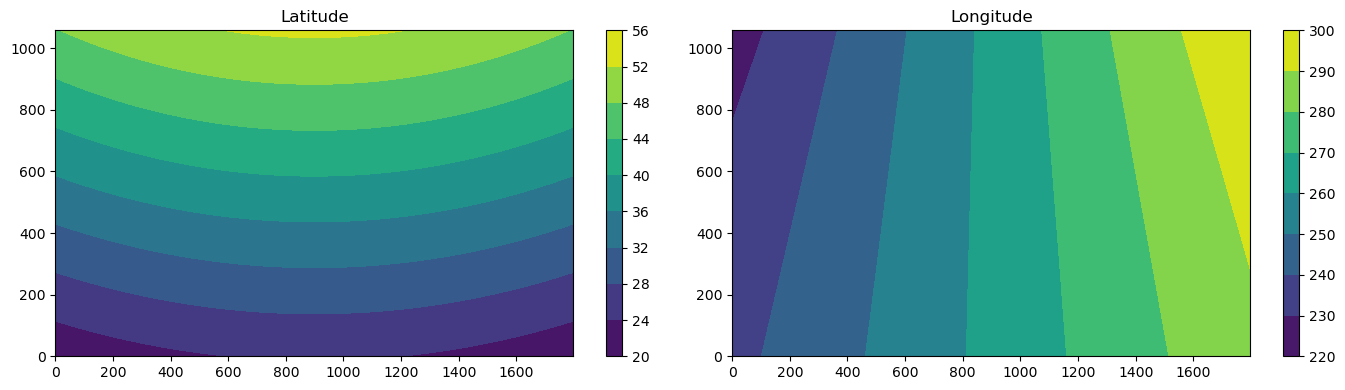

In [ ]:
# Create figure and subplots
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(14, 4))

# First subplot - Latitude
im1 = ax1.contourf(t2m_ds.latitude)
ax1.set_title('Latitude')
plt.colorbar(im1, ax=ax1)

# Second subplot - Longitude 
im2 = ax2.contourf(t2m_ds.longitude)
ax2.set_title('Longitude')
plt.colorbar(im2, ax=ax2)

# Adjust layout to prevent overlap
plt.tight_layout()

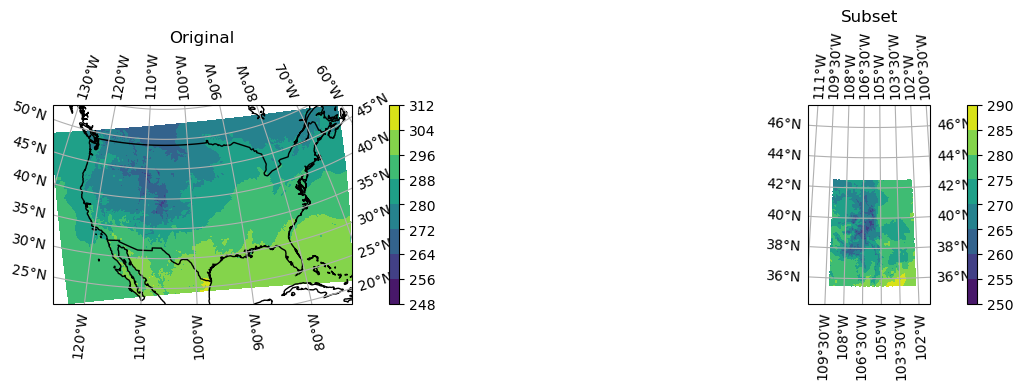

In [27]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Create AzimuthalEquidistant projection
proj = ccrs.AzimuthalEquidistant(central_longitude=-105.7, central_latitude=39)

# Create figure and subplots with projection
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(14, 4),
                              subplot_kw={'projection': proj})

# First subplot - Original data
im1 = ax1.contourf(t2m_ds.longitude.values, t2m_ds.latitude.values, t2m_ds['t2m'].values,
                   transform=ccrs.PlateCarree())
ax1.set_title('Original')
ax1.coastlines()
ax1.add_feature(cfeature.BORDERS)
ax1.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
plt.colorbar(im1, ax=ax1)

# Second subplot - Subset data
subset = sel_region(t2m_ds['t2m'], [39, 360-105.7], 7)
im2 = ax2.contourf(subset.longitude.values, subset.latitude.values, subset.values,
                   transform=ccrs.PlateCarree())
ax2.set_title('Subset')
ax2.coastlines()
ax2.add_feature(cfeature.BORDERS)
ax2.gridlines(draw_labels=True, dms=True, x_inline=False, y_inline=False)
plt.colorbar(im2, ax=ax2)

plt.tight_layout()

# Generate a time series

In [2]:
# https://herbie.readthedocs.io/en/stable/gallery/noaa_models/hrrr.html
H = FastHerbie(
    [get_latest_forecast_cycle()],
    model="hrrr",
    product="sfc",
    fxx=list(range(6, 31)),
)

points = pd.DataFrame({"longitude": [-105.082396, -80.172745], # [Fort Collins, Erie]
                       "latitude": [40.548843, 42.083850],
                       })

t2m_ds = H.xarray("TMP:2 m above", backend_kwargs={'decode_times':False}
                  ).herbie.pick_points(points, method="nearest")

t2m_ds

t2m_ds = (t2m_ds['t2m'] - 273.15) * 1.8 + 32

/Users/jglarson/miniconda3/envs/weather-output/lib/python3.13/site-packages/xarray/backends/plugins.py:75: RuntimeWarning: Engine 'gini' loading failed:
cannot inherit frozen dataclass from a non-frozen one
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)


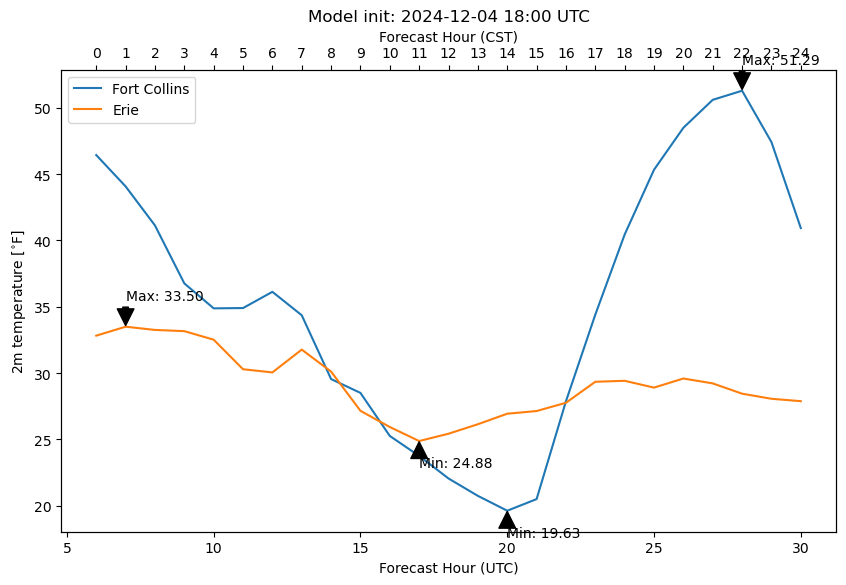

In [3]:
# Create the plot
fig, ax1 = plt.subplots(figsize=(10, 6))

# Add title with datetime_index
plt.title(f"Model init: {get_latest_forecast_cycle().strftime('%Y-%m-%d %H:%M')} UTC")

fort_collins = t2m_ds.sel(point=0).values
city2 = t2m_ds.sel(point=1).values

# Plot on primary axis (UTC)
ax1.plot(np.arange(6,31), fort_collins, label='Fort Collins')
ax1.plot(np.arange(6,31), city2, label='Erie')
ax1.set_xlabel('Forecast Hour (UTC)')
ax1.set_ylabel(r'2m temperature [$^{\circ}$F]')

# Create secondary x-axis for CST
ax2 = ax1.twiny()
cst_hours = np.arange(0,25)  # UTC-6
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(np.arange(6,31))
ax2.set_xticklabels([str(h-6) for h in range(6,31)])
ax2.set_xlabel('Forecast Hour (CST)')

# Annotate max and min for Fort Collins
max_fc = np.max(fort_collins)
min_fc = np.min(fort_collins)
max_fc_idx = np.argmax(fort_collins)
min_fc_idx = np.argmin(fort_collins)

plt.annotate(f'Max: {max_fc:.2f}', xy=(max_fc_idx + 6, max_fc), xytext=(max_fc_idx + 6, max_fc + 2),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.annotate(f'Min: {min_fc:.2f}', xy=(min_fc_idx + 6, min_fc), xytext=(min_fc_idx + 6, min_fc - 2),
             arrowprops=dict(facecolor='black', shrink=0.05))

# Annotate max and min for Wichita Falls
max_wf = np.max(city2)
min_wf = np.min(city2)
max_wf_idx = np.argmax(city2)
min_wf_idx = np.argmin(city2)

plt.annotate(f'Max: {max_wf:.2f}', xy=(max_wf_idx + 6, max_wf), xytext=(max_wf_idx + 6, max_wf + 2),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.annotate(f'Min: {min_wf:.2f}', xy=(min_wf_idx + 6, min_wf), xytext=(min_wf_idx + 6, min_wf - 2),
             arrowprops=dict(facecolor='black', shrink=0.05))


# Add legend
ax1.legend()

plt.show()

## Precip

# To DO: Figure out how to correctly zero the total precip (ie, if it's snowing prior to midnight, I need to remove that precip from the tp). Also, I realized I'm pulling the incorrect model forecasts since the time zone changed. Automate this? Maybe a package which knows the time zone based on coordinates. Finally, change the second plot axis to represent the change in time zone

In [ ]:
H = FastHerbie(
    [get_latest_forecast_cycle()],
    model="hrrr",
    product="sfc",
    fxx=list(range(6, 31)),
)
H

In [15]:
# Load in the data
H = FastHerbie(
    [get_latest_forecast_cycle()],
    model="hrrr",
    product="sfc",
    fxx=list(range(6, 31)),
)
                
tp = H.xarray("APCP", backend_kwargs={'decode_times':False}
              ).herbie.pick_points(points, method="nearest"
                                   )['tp']
tp = tp * 0.0393701  # Convert mm (1 kg m^-2 = 1 mm) to inches
tp


<xarray.DataArray 'tp' (step: 25, point: 2)> Size: 200B
array([[0.        , 0.05393704],
       [0.        , 0.06220476],
       [0.        , 0.0755906 ],
       [0.        , 0.09055123],
       [0.        , 0.09763785],
       [0.        , 0.09921265],
       [0.        , 0.09921265],
       [0.        , 0.09921265],
       [0.        , 0.09921265],
       [0.        , 0.09921265],
       [0.        , 0.09960636],
       [0.        , 0.10078745],
       [0.        , 0.10118116],
       [0.        , 0.10118116],
       [0.        , 0.10433077],
       [0.        , 0.10708667],
       [0.        , 0.10708667],
       [0.        , 0.10787408],
       [0.        , 0.11102368],
       [0.        , 0.12047251],
       [0.        , 0.12086621],
       [0.        , 0.12125991],
       [0.        , 0.12125991],
       [0.        , 0.12125991],
       [0.        , 0.12165361]], dtype=float32)
Coordinates:
    time                 int64 8B 1733421600
  * step                 (step) float64 200B 6.0 7.0 8.0 9.0 ... 28.0 29.0 30.0
    surface              float64 8B 0.0
    latitude             (point) float64 16B 40.55 42.09
    longitude            (point) float64 16B 254.9 279.8
    valid_time           (step) float64 200B 1.733e+09 1.733e+09 ... 1.734e+09
    gribfile_projection  object 8B None
    point_grid_distance  (point) float64 16B 0.9413 0.4454
    point_longitude      (point) float64 16B -105.1 -80.17
    point_latitude       (point) float64 16B 40.55 42.08
Dimensions without coordinates: point

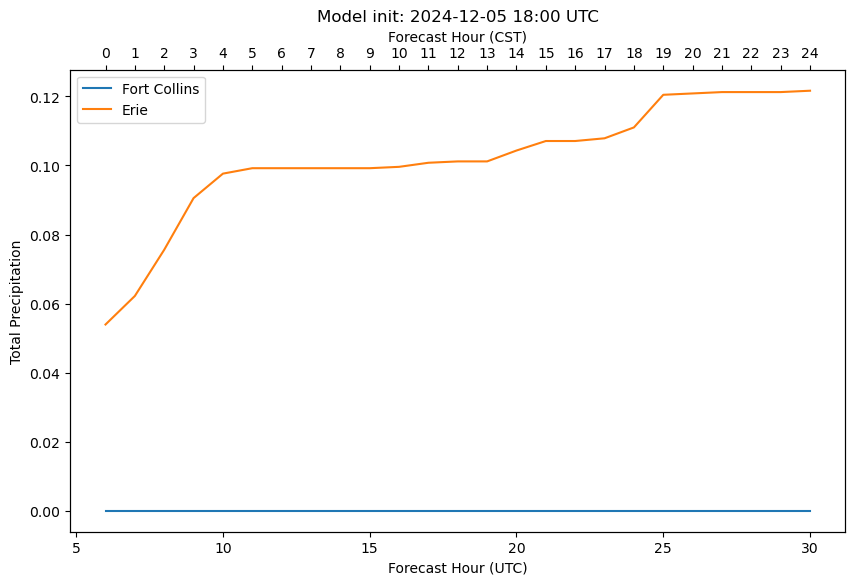

In [14]:

# Create the plot
fig, ax1 = plt.subplots(figsize=(10, 6))

# Add title with datetime_index
plt.title(f"Model init: {get_latest_forecast_cycle().strftime('%Y-%m-%d %H:%M')} UTC")

fort_collins = tp.sel(point=0).values
city2 = tp.sel(point=1).values

# Plot on primary axis (UTC)
ax1.plot(np.arange(6,31), fort_collins, label='Fort Collins')
ax1.plot(np.arange(6,31), city2, label='Erie')
ax1.set_xlabel('Forecast Hour (UTC)')
ax1.set_ylabel('Total Precipitation')

# Create secondary x-axis for CST
ax2 = ax1.twiny()
cst_hours = np.arange(0,25)  # UTC-6
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(np.arange(6,31))
ax2.set_xticklabels([str(h-6) for h in range(6,31)])
ax2.set_xlabel('Forecast Hour (CST)')

# Add legend
ax1.legend()

plt.show()


# TO DO: convert tp from Kg per square meter to inches. Potentially 0.039370079003585

# Add NBM

In [35]:
# dates = pd.date_range("2024-11-21 18:00", periods=1, freq="1h")
today = pd.Timestamp.now().date()
dates = pd.DatetimeIndex([pd.Timestamp(f"{today} 18:00")])

H = FastHerbie(dates, model="nbm", fxx=list(range(6, 31)), product="co")
H.inventory(":TMP:2 m above ground:.*fcst:nan")

points = pd.DataFrame({"longitude": [-105.082396, -80.172745], # [Fort Collins, Erie]
                       "latitude": [40.548843, 42.083850],
                       })

ds = H.xarray(":TMP:2 m above ground:.*fcst:nan", backend_kwargs={'decode_times':False}
              ).herbie.pick_points(points, method="nearest")

t2m_ds = (ds['t2m'] - 273.15) * 1.8 + 32

👨🏻‍🏭 Created directory: [/Users/jglarson/data/nbm/20241202]


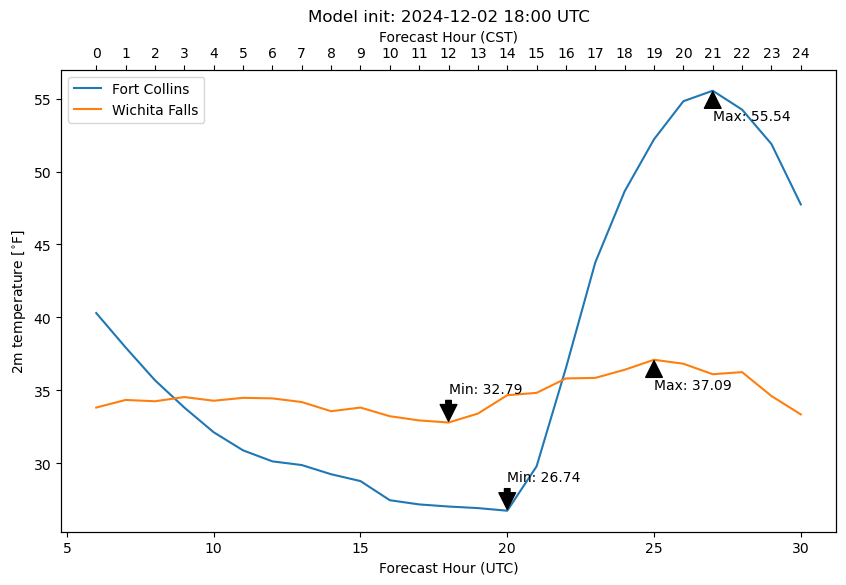

In [36]:
# Create the plot
fig, ax1 = plt.subplots(figsize=(10, 6))

# Add title with datetime_index
plt.title(f"Model init: {dates[0].strftime('%Y-%m-%d %H:%M')} UTC")

fort_collins = t2m_ds.sel(point=0).values
city2 = t2m_ds.sel(point=1).values

# Plot on primary axis (UTC)
ax1.plot(np.arange(6,31), fort_collins, label='Fort Collins')
ax1.plot(np.arange(6,31), city2, label='Wichita Falls')
ax1.set_xlabel('Forecast Hour (UTC)')
ax1.set_ylabel(r'2m temperature [$^{\circ}$F]')

# Create secondary x-axis for CST
ax2 = ax1.twiny()
cst_hours = np.arange(0,25)  # UTC-6
ax2.set_xlim(ax1.get_xlim())
ax2.set_xticks(np.arange(6,31))
ax2.set_xticklabels([str(h-6) for h in range(6,31)])
ax2.set_xlabel('Forecast Hour (CST)')

# Annotate max and min for Fort Collins
max_fc = np.max(fort_collins)
min_fc = np.min(fort_collins)
max_fc_idx = np.argmax(fort_collins)
min_fc_idx = np.argmin(fort_collins)

plt.annotate(f'Max: {max_fc:.2f}', xy=(max_fc_idx + 6, max_fc), xytext=(max_fc_idx + 6, max_fc - 2),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.annotate(f'Min: {min_fc:.2f}', xy=(min_fc_idx + 6, min_fc), xytext=(min_fc_idx + 6, min_fc + 2),
             arrowprops=dict(facecolor='black', shrink=0.05))

# Annotate max and min for Wichita Falls
max_wf = np.max(city2)
min_wf = np.min(city2)
max_wf_idx = np.argmax(city2)
min_wf_idx = np.argmin(city2)

plt.annotate(f'Max: {max_wf:.2f}', xy=(max_wf_idx + 6, max_wf), xytext=(max_wf_idx + 6, max_wf - 2),
             arrowprops=dict(facecolor='black', shrink=0.05))
plt.annotate(f'Min: {min_wf:.2f}', xy=(min_wf_idx + 6, min_wf), xytext=(min_wf_idx + 6, min_wf + 2),
             arrowprops=dict(facecolor='black', shrink=0.05))


# Add legend
ax1.legend()

plt.show()

# To Do: Generate verificatoin statistics to know what model is good and bad